# NumCompute Stream demonstration

This notebook loads a synthetic CSV and processes it in chunks of 50 rows.
The pipeline combines mean imputation, standard scaling and a buffered
decision tree.

After 200 rows of initial training, each new chunk is evaluated before
training. Results include classification metrics, accuracy plots,
estimated pipeline memory and a comparison of three buffer sizes.

Run all cells in order. Generated plots and CSV results are saved in
`demo/outputs`.

In [11]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt

# Find the project folder whether the notebook starts in demo or its parent.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "numcompute_stream").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "numcompute_stream").is_dir():
    raise RuntimeError("Open this notebook from the numcompute-review project")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from numcompute.io import load_csv
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.stats import StreamingStats
from numcompute_stream.metrics import StreamingMetrics
from numcompute_stream.visualise import (
    plot_metric_over_time,
    compare_models,
    plot_predictions_vs_ground_truth,
)

print("Imports successful")
print("Project folder:", PROJECT_ROOT)

Imports successful
Project folder: c:\Kathy\Adelaide University\Artificial Intelligence and ML\Assignment 2.2\numcompute-review


In [12]:
# Create reproducible synthetic data for the streaming demonstration.
rng = np.random.default_rng(42)

X_complete = rng.uniform(0.0, 10.0, size=(1200, 2))

# Three classes defined by two decision boundaries.
y_generated = np.where(
    X_complete[:, 0] < 4.0,
    0,
    np.where(X_complete[:, 1] < 6.0, 1, 2),
)

# Remove approximately 5% of feature values to exercise imputation.
X_missing = X_complete.copy()
missing_mask = rng.random(X_missing.shape) < 0.05
X_missing[missing_mask] = np.nan

DATA_PATH = PROJECT_ROOT / "demo" / "data" / "stream_synthetic.csv"

np.savetxt(
    DATA_PATH,
    np.column_stack([X_missing, y_generated]),
    delimiter=",",
    header="feature_1,feature_2,label",
    comments="",
    fmt="%.8f",
)

print("Synthetic dataset saved:", DATA_PATH.name)
print("Rows:", len(y_generated))
print("Missing feature values:", np.isnan(X_missing).sum())
print("Class counts:", np.bincount(y_generated))

Synthetic dataset saved: stream_synthetic.csv
Rows: 1200
Missing feature values: 119
Class counts: [497 428 275]


In [13]:
# Load the CSV through our custom I/O function.
data = load_csv(
    str(DATA_PATH),
    delimiter=",",
    skip_header=1,
    missing="propagate",
)

# The first two columns are features; the last column is the label.
X = data[:, :2]
y = data[:, 2].astype(int)

CHUNK_SIZE = 50

X_chunks = [
    X[start:start + CHUNK_SIZE]
    for start in range(0, len(X), CHUNK_SIZE)
]
y_chunks = [
    y[start:start + CHUNK_SIZE]
    for start in range(0, len(y), CHUNK_SIZE)
]

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Number of chunks:", len(X_chunks))
print("Rows in first chunk:", len(X_chunks[0]))
print("Missing feature values:", np.isnan(X).sum())

Feature shape: (1200, 2)
Label shape: (1200,)
Number of chunks: 24
Rows in first chunk: 50
Missing feature values: 119


In [14]:
# Create the streaming pipeline.
BUFFER_SIZE = 100
WARMUP_ROWS = 200

pipeline = Pipeline([
    ("impute", SimpleImputer()),
    ("scale", StandardScaler()),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        buffer_size=BUFFER_SIZE,
    )),
])

trainer = StreamTrainer(pipeline)
metrics = StreamingMetrics()
rolling_metrics = StreamingMetrics(window_size=200)
stats = StreamingStats()

scored_chunks = []
rolling_accuracy = []
rows_received = 0

for chunk_number, (X_chunk, y_chunk) in enumerate(
    zip(X_chunks, y_chunks), start=1
):
    if rows_received >= WARMUP_ROWS:
        # Evaluate before this chunk updates the model or preprocessing.
        predictions = pipeline.predict(X_chunk)
        accuracy = trainer.score_chunk(X_chunk, y_chunk)

        metrics.update(y_chunk, predictions)
        rolling_metrics.update(y_chunk, predictions)

        scored_chunks.append(chunk_number)
        rolling_accuracy.append(
            rolling_metrics.result()["accuracy"]
        )

        print(
            f"Chunk {chunk_number:02d}: "
            f"accuracy={accuracy:.3f}, "
            f"cumulative={metrics.result()['accuracy']:.3f}"
        )
    else:
        print(f"Chunk {chunk_number:02d}: initial training")

    # Update statistics on the original numeric features.
    stats.update_stats(X_chunk)

    # Train only after evaluation, or during initial training.
    trainer.fit_chunk(X_chunk, y_chunk)
    rows_received += len(y_chunk)

summary = metrics.result()

print("\nEvaluated samples:", summary["n_samples"])
print("Overall accuracy:", round(summary["accuracy"], 3))
print("Macro F1:", round(summary["macro_f1"], 3))
print("Classes:", summary["classes"])
print("Confusion matrix:\n", summary["confusion_matrix"])

Chunk 01: initial training
Chunk 02: initial training
Chunk 03: initial training
Chunk 04: initial training
Chunk 05: accuracy=0.860, cumulative=0.860
Chunk 06: accuracy=0.960, cumulative=0.910
Chunk 07: accuracy=0.920, cumulative=0.913
Chunk 08: accuracy=0.980, cumulative=0.930
Chunk 09: accuracy=0.920, cumulative=0.928
Chunk 10: accuracy=0.860, cumulative=0.917
Chunk 11: accuracy=0.840, cumulative=0.906
Chunk 12: accuracy=0.960, cumulative=0.912
Chunk 13: accuracy=0.960, cumulative=0.918
Chunk 14: accuracy=0.960, cumulative=0.922
Chunk 15: accuracy=0.960, cumulative=0.925
Chunk 16: accuracy=0.960, cumulative=0.928
Chunk 17: accuracy=0.960, cumulative=0.931
Chunk 18: accuracy=0.960, cumulative=0.933
Chunk 19: accuracy=0.920, cumulative=0.932
Chunk 20: accuracy=0.880, cumulative=0.929
Chunk 21: accuracy=0.920, cumulative=0.928
Chunk 22: accuracy=0.900, cumulative=0.927
Chunk 23: accuracy=0.980, cumulative=0.929
Chunk 24: accuracy=0.900, cumulative=0.928

Evaluated samples: 1000
Overall

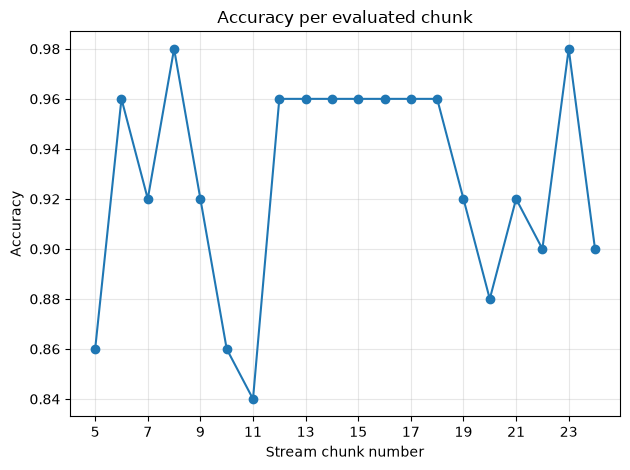

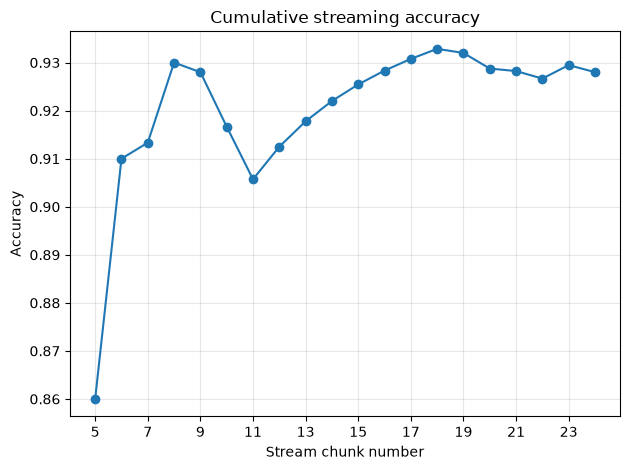

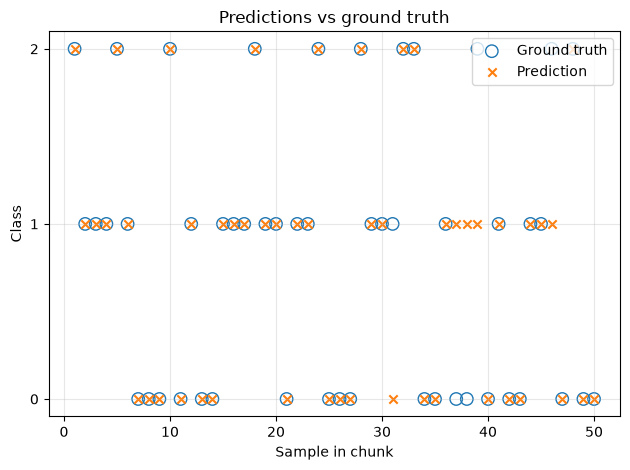

Plots saved in: c:\Kathy\Adelaide University\Artificial Intelligence and ML\Assignment 2.2\numcompute-review\demo\outputs


In [15]:
# Save plots generated from the measured streaming results.
OUTPUT_DIR = PROJECT_ROOT / "demo" / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

chunk_accuracy = [entry["accuracy"] for entry in trainer.history]
cumulative_accuracy = [
    entry["cumulative_accuracy"] for entry in trainer.history
]

fig, ax = plot_metric_over_time(
    chunk_accuracy,
    "Accuracy per evaluated chunk",
    "Accuracy",
    show=False,
)
ax.set_xticks(range(1, len(scored_chunks) + 1, 2))
ax.set_xticklabels(scored_chunks[::2])
ax.set_xlabel("Stream chunk number")
fig.savefig(OUTPUT_DIR / "chunk_accuracy.png", bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plot_metric_over_time(
    cumulative_accuracy,
    "Cumulative streaming accuracy",
    "Accuracy",
    show=False,
)
ax.set_xticks(range(1, len(scored_chunks) + 1, 2))
ax.set_xticklabels(scored_chunks[::2])
ax.set_xlabel("Stream chunk number")
fig.savefig(OUTPUT_DIR / "cumulative_accuracy.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# predictions still contains the final chunk's predictions BEFORE training.
fig, ax = plot_predictions_vs_ground_truth(
    y_chunks[-1],
    predictions,
    save_path=OUTPUT_DIR / "latest_chunk_predictions.png",
    show=False,
)
plt.show()
plt.close(fig)

print("Plots saved in:", OUTPUT_DIR)

In [16]:
from time import perf_counter


def evaluate_buffer(buffer_size):
    """Evaluate one buffer size using the same stream and warm-up."""
    pipe = Pipeline([
        ("impute", SimpleImputer()),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=5,
            buffer_size=buffer_size,
        )),
    ])

    evaluation = StreamingMetrics()
    accuracies = []
    update_seconds = 0.0
    retraining_update_seconds = 0.0
    retrain_count = 0
    pending_rows = 0
    received_rows = 0

    for X_chunk, y_chunk in zip(X_chunks, y_chunks):
        # All models are evaluated on exactly the same unseen rows.
        if received_rows >= WARMUP_ROWS:
            predicted = pipe.predict(X_chunk)
            evaluation.update(y_chunk, predicted)
            accuracies.append(float(np.mean(predicted == y_chunk)))

        pending_rows += len(X_chunk)
        will_retrain = pending_rows >= buffer_size

        started = perf_counter()
        pipe.partial_fit(X_chunk, y_chunk)
        elapsed = perf_counter() - started
        update_seconds += elapsed

        if will_retrain:
            # Includes preprocessing and buffering as well as tree fitting.
            retraining_update_seconds += elapsed
            retrain_count += 1
            pending_rows = 0

        received_rows += len(y_chunk)

    return {
        "buffer_size": buffer_size,
        "accuracy": evaluation.result()["accuracy"],
        "evaluated_samples": evaluation.result()["n_samples"],
        "update_seconds": update_seconds,
        "retraining_update_seconds": retraining_update_seconds,
        "retrains": retrain_count,
        "chunk_accuracy": accuracies,
    }


# Repeat timings three times and report their median.
buffer_results = {}

for size in [50, 100, 200]:
    runs = [evaluate_buffer(size) for _ in range(3)]
    result = runs[0].copy()
    result["update_seconds"] = float(np.median([
        run["update_seconds"] for run in runs
    ]))
    result["retraining_update_seconds"] = float(np.median([
        run["retraining_update_seconds"] for run in runs
    ]))
    buffer_results[size] = result

    print(
        f"Buffer={size:3d} | "
        f"accuracy={result['accuracy']:.3f} | "
        f"evaluated={result['evaluated_samples']} | "
        f"retrains={result['retrains']} | "
        f"total update time={result['update_seconds']:.4f}s | "
        f"retraining updates={result['retraining_update_seconds']:.4f}s"
    )

Buffer= 50 | accuracy=0.902 | evaluated=1000 | retrains=24 | total update time=0.0696s | retraining updates=0.0696s
Buffer=100 | accuracy=0.928 | evaluated=1000 | retrains=12 | total update time=0.0530s | retraining updates=0.0474s
Buffer=200 | accuracy=0.947 | evaluated=1000 | retrains=6 | total update time=0.0410s | retraining updates=0.0345s


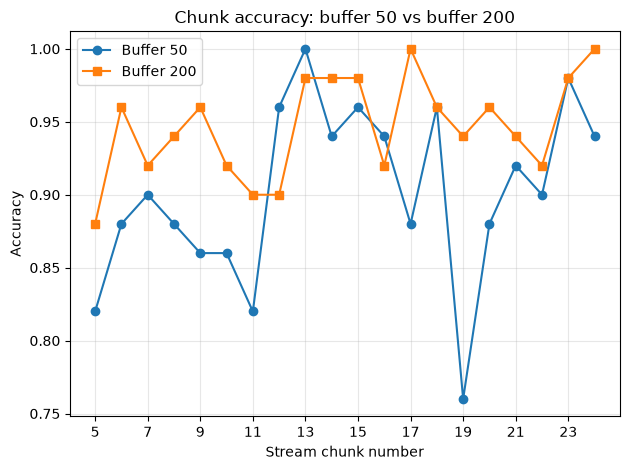

Comparison plot and benchmark CSV saved.


In [17]:
# Compare measured chunk accuracy for two buffer sizes.
fig, ax = compare_models(
    buffer_results[50]["chunk_accuracy"],
    buffer_results[200]["chunk_accuracy"],
    ["Buffer 50", "Buffer 200"],
    show=False,
)
ax.set_title("Chunk accuracy: buffer 50 vs buffer 200")
ax.set_ylabel("Accuracy")
ax.set_xticks(range(1, len(scored_chunks) + 1, 2))
ax.set_xticklabels(scored_chunks[::2])
ax.set_xlabel("Stream chunk number")
fig.savefig(
    OUTPUT_DIR / "buffer_comparison.png",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Save the benchmark summary for the report.
benchmark_rows = np.array([
    [
        size,
        buffer_results[size]["accuracy"],
        buffer_results[size]["evaluated_samples"],
        buffer_results[size]["retrains"],
        buffer_results[size]["update_seconds"],
        buffer_results[size]["retraining_update_seconds"],
    ]
    for size in [50, 100, 200]
])

np.savetxt(
    OUTPUT_DIR / "buffer_benchmark.csv",
    benchmark_rows,
    delimiter=",",
    header=(
        "buffer_size,accuracy,evaluated_samples,retrains,"
        "update_seconds,retraining_update_seconds"
    ),
    comments="",
    fmt=["%d", "%.6f", "%d", "%d", "%.8f", "%.8f"],
)

print("Comparison plot and benchmark CSV saved.")

In [18]:
print(trainer.history[-1])

{'accuracy': 0.9, 'cumulative_accuracy': 0.928, 'prediction_peak_bytes': 6105, 'estimator_bytes': 11484}


Latest estimated pipeline memory: 11484 bytes


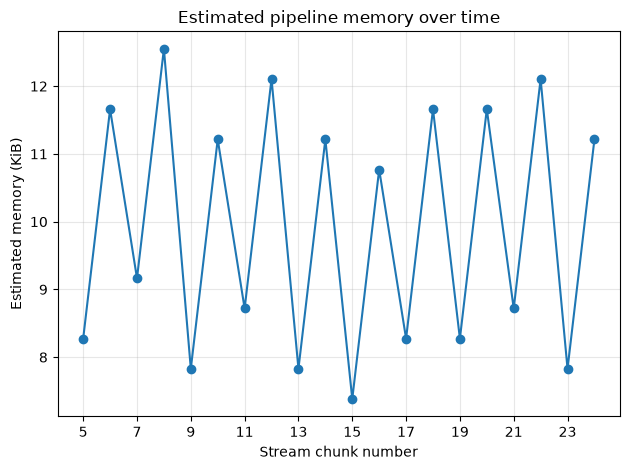

Memory plot and evaluation log saved.


In [19]:
# Show and save estimated pipeline memory for each evaluated chunk.
memory_bytes = [
    entry["estimator_bytes"] for entry in trainer.history
]

print("Latest estimated pipeline memory:", memory_bytes[-1], "bytes")

fig, ax = plot_metric_over_time(
    np.array(memory_bytes) / 1024,
    "Estimated pipeline memory over time",
    "Estimated memory (KiB)",
    show=False,
)
ax.set_xticks(range(1, len(scored_chunks) + 1, 2))
ax.set_xticklabels(scored_chunks[::2])
ax.set_xlabel("Stream chunk number")
fig.savefig(
    OUTPUT_DIR / "estimated_pipeline_memory.png",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

np.savetxt(
    OUTPUT_DIR / "stream_evaluation.csv",
    np.column_stack([
        scored_chunks,
        chunk_accuracy,
        cumulative_accuracy,
        memory_bytes,
    ]),
    delimiter=",",
    header="chunk,accuracy,cumulative_accuracy,estimator_bytes",
    comments="",
    fmt=["%d", "%.6f", "%.6f", "%d"],
)

print("Memory plot and evaluation log saved.")

## Results and limitations

With a buffer of 100 rows, cumulative accuracy was 92.8% over 1,000
evaluated samples. Buffer sizes of 50 and 200 achieved 90.2% and 94.7%,
with 24 and 6 retrains respectively.

These results describe this synthetic dataset. They do not show that a
larger buffer always performs better. Update times include preprocessing
and training and can vary between runs.

Memory values estimate the pipeline's retained objects, not total process
RAM. The CSV is loaded into memory before being divided into chunks.